#### To build a hybrid anomaly detection model using a sparse autoencoder, Isolation Forest, and XGBoost, follow these steps: First, load and clean your data to ensure it is accurate and relevant. Next, select key features and split the dataset into training and testing sets. Normalize the features through scaling to ensure they are equally weighted. Use a sparse autoencoder to reduce the dimensionality of the data, facilitating more efficient processing. Apply an Isolation Forest to initially identify and isolate potential anomalies. Further refine this detection with XGBoost, enhancing the model's accuracy, especially for subtle anomalies. Finally, evaluate the model using precision, recall, F1-score, and a confusion matrix to assess its overall performance and accuracy. This sequential approach leverages each method's strengths to create a robust and effective anomaly detection system.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import IsolationForest
from xgboost import XGBClassifier
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras import regularizers
from sklearn.preprocessing import LabelEncoder


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier
from scipy.stats import wilcoxon

C:\Users\sebha\AppData\Local\Temp\ipykernel_36788\1950101505.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in data.select_dtypes(include=['object']).columns:


1527/1527 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step


C:\Users\sebha\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:51:15] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Precision: 0.828
Recall: 0.856
F1 Score: 0.825
              precision    recall  f1-score   support

           0       0.60      0.21      0.31      1511
           1       0.87      0.97      0.92      8258

    accuracy                           0.86      9769
   macro avg       0.73      0.59      0.61      9769
weighted avg       0.83      0.86      0.82      9769



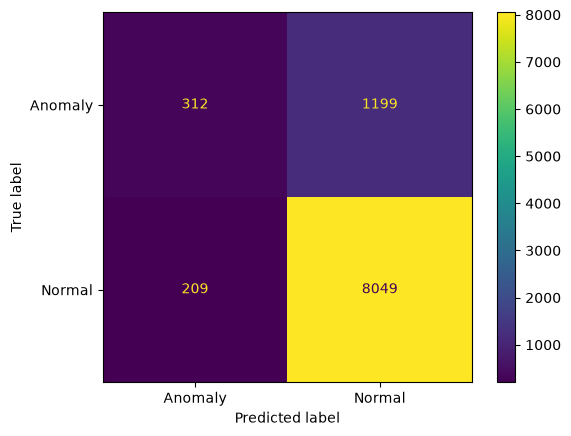

In [2]:

def hybrid_anomaly_detection_MAADM():
    # Load data from a CSV file
    data = pd.read_csv('adultdata.csv')
    data.dropna(axis=0, inplace=True)
    
    #convert all the values in the columns into numeric
    label_encoder = LabelEncoder()
    for column in data.select_dtypes(include=['object']).columns:
        data[column] = label_encoder.fit_transform(data[column])
    data.dropna(axis=0, inplace=True)
    
    X = data.drop('Hours_per_week', axis=1)  # This is the target variable
    y_cont = data['Hours_per_week']
    
    y = np.where(y_cont > 30, 1, 0)  # Define `threshold` based on the dataset
    
    # Select top k features; k might be adjusted based on the dataset
    selector = SelectKBest(f_classif, k=5)
    X_selected = selector.fit_transform(X, y)
    
    
    # Dimensionality reduction with sparse autoencoder
    input_dim = X_selected.shape[1]
    encoding_dim = 32  # Dimension of the encoding layer
    input_layer = Input(shape=(input_dim,))
    encoded = Dense(encoding_dim, activation='relu', activity_regularizer=regularizers.l1(10e-5))(input_layer)
    decoded = Dense(input_dim, activation='sigmoid')(encoded)
    autoencoder = Model(inputs=input_layer, outputs=decoded)
    autoencoder.compile(optimizer='adam', loss='mean_squared_error')
    autoencoder.fit(X_selected, X_selected, epochs=50, batch_size=256, shuffle=True, verbose=0)
    
    encoder = Model(inputs=input_layer, outputs=encoded)
    X_encoded = encoder.predict(X_selected)
    
    # Split the data into train and test sets
    X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
    
    # Scale the features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Use Isolation Forest to identify normal data points
    iso_forest = IsolationForest(contamination=0.1, n_estimators=100, random_state=42)
    iso_forest.fit(X_train_scaled)
    iso_preds = iso_forest.predict(X_train_scaled)
    
    # Filter only normal data points as identified by Isolation Forest
    normal_indices = np.where(iso_preds == 1)[0]  # Assuming '1' is normal
    X_train_normal = X_train_scaled[normal_indices]
    y_train_normal = y_train[normal_indices]
    
    # Train XGBoost on the filtered normal data
    xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
    xgb.fit(X_train_normal, y_train_normal)
    
    # Predict using XGBoost on the test set
    xgb_preds = xgb.predict(X_test_scaled)
    
    # Evaluate the final outcome from XGBoost
    precision = precision_score(y_test, xgb_preds, average='weighted', zero_division=0)
    recall = recall_score(y_test, xgb_preds, average='weighted', zero_division=0)
    f1 = f1_score(y_test, xgb_preds, average='weighted', zero_division=0)
    
    print(f'Precision: {precision:.3f}')
    print(f'Recall: {recall:.3f}')
    print(f'F1 Score: {f1:.3f}')
    
    print(classification_report(y_test, xgb_preds))


    # Display the confusion matrix
    cm = confusion_matrix(y_test, xgb_preds, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Anomaly', 'Normal'])
    disp.plot()
    plt.show()
    

hybrid_anomaly_detection_MAADM()




Running MAADM with seed: 5


C:\Users\sebha\AppData\Local\Temp\ipykernel_36788\2147051521.py:44: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


Precision: 0.8502 | Recall: 0.8706 | F1: 0.8523
              precision    recall  f1-score   support

     Class 0       0.60      0.31      0.41      1307
     Class 1       0.89      0.97      0.93      7738

    accuracy                           0.87      9045
   macro avg       0.75      0.64      0.67      9045
weighted avg       0.85      0.87      0.85      9045



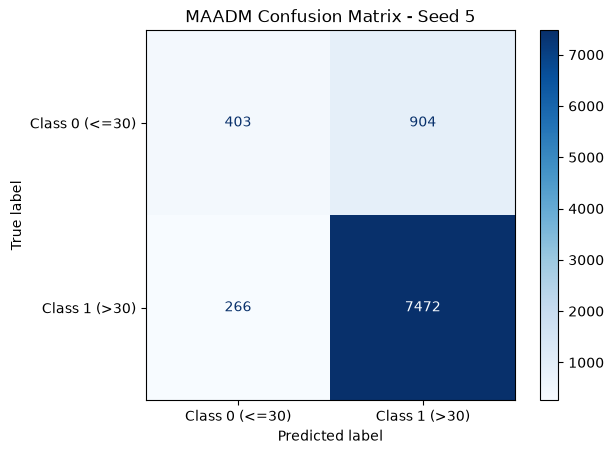


Running MAADM with seed: 21


C:\Users\sebha\AppData\Local\Temp\ipykernel_36788\2147051521.py:44: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


Precision: 0.8518 | Recall: 0.8725 | F1: 0.8477
              precision    recall  f1-score   support

     Class 0       0.65      0.25      0.37      1307
     Class 1       0.89      0.98      0.93      7738

    accuracy                           0.87      9045
   macro avg       0.77      0.62      0.65      9045
weighted avg       0.85      0.87      0.85      9045



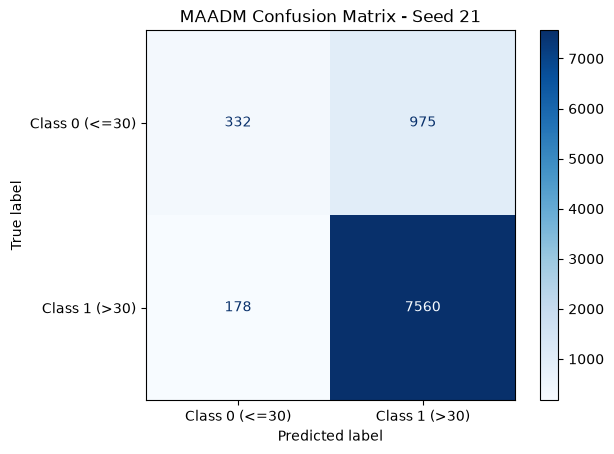


Running MAADM with seed: 42


C:\Users\sebha\AppData\Local\Temp\ipykernel_36788\2147051521.py:44: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


Precision: 0.8551 | Recall: 0.8745 | F1: 0.8520
              precision    recall  f1-score   support

     Class 0       0.66      0.28      0.39      1307
     Class 1       0.89      0.98      0.93      7738

    accuracy                           0.87      9045
   macro avg       0.77      0.63      0.66      9045
weighted avg       0.86      0.87      0.85      9045



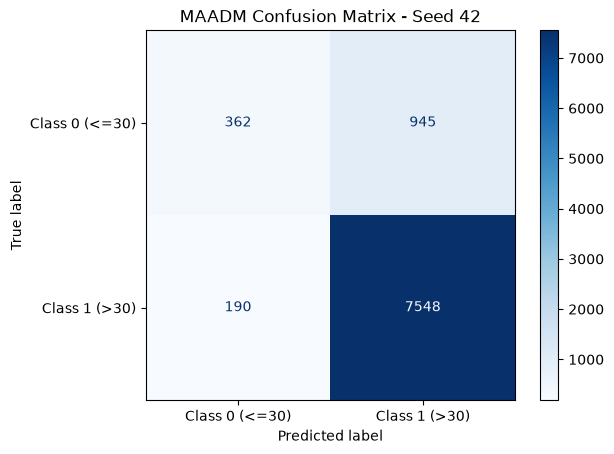


Running MAADM with seed: 77


C:\Users\sebha\AppData\Local\Temp\ipykernel_36788\2147051521.py:44: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


Precision: 0.8556 | Recall: 0.8748 | F1: 0.8519
              precision    recall  f1-score   support

     Class 0       0.66      0.27      0.39      1307
     Class 1       0.89      0.98      0.93      7738

    accuracy                           0.87      9045
   macro avg       0.77      0.63      0.66      9045
weighted avg       0.86      0.87      0.85      9045



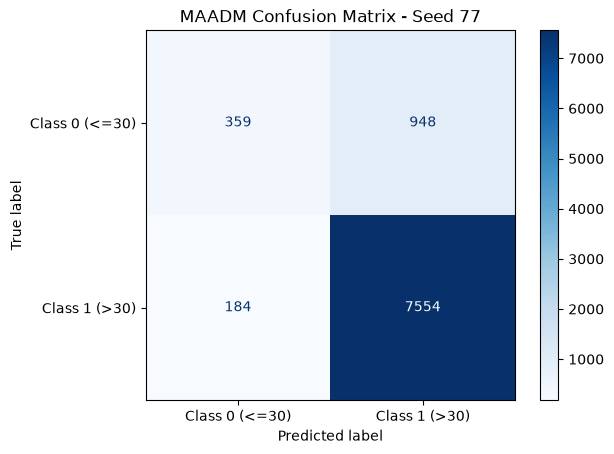


Running MAADM with seed: 100


C:\Users\sebha\AppData\Local\Temp\ipykernel_36788\2147051521.py:44: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(


Precision: 0.8575 | Recall: 0.8758 | F1: 0.8575
              precision    recall  f1-score   support

     Class 0       0.64      0.32      0.43      1307
     Class 1       0.89      0.97      0.93      7738

    accuracy                           0.88      9045
   macro avg       0.77      0.64      0.68      9045
weighted avg       0.86      0.88      0.86      9045



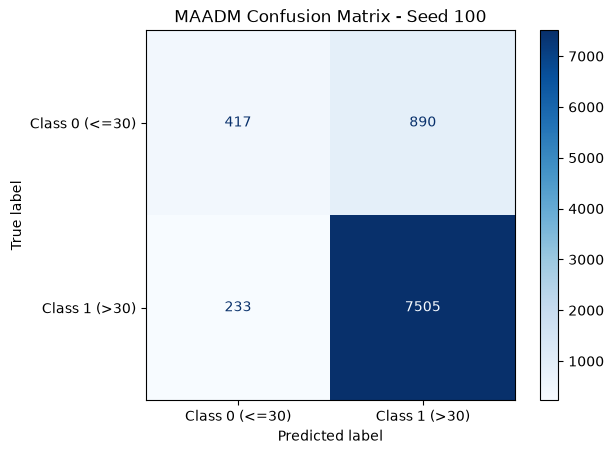


Individual Seed Results
 Seed  Precision   Recall       F1  Class1_Precision  Class1_Recall  Class1_F1
    5   0.850214 0.870647 0.852325          0.892073       0.965624   0.927392
   21   0.851838 0.872526 0.847691          0.885764       0.976997   0.929146
   42   0.855073 0.874516 0.851953          0.888732       0.975446   0.930072
   77   0.855644 0.874848 0.851950          0.888497       0.976221   0.930296
  100   0.857506 0.875843 0.857530          0.893985       0.969889   0.930391

MAADM: Mean ± Standard Deviation
          Metric     Mean      Std       Mean ± SD
       Precision 0.854055 0.002964 0.8541 ± 0.0030
          Recall 0.873676 0.002078 0.8737 ± 0.0021
              F1 0.852290 0.003494 0.8523 ± 0.0035
Class1_Precision 0.889810 0.003233 0.8898 ± 0.0032
   Class1_Recall 0.972835 0.004906 0.9728 ± 0.0049
       Class1_F1 0.929460 0.001256 0.9295 ± 0.0013


In [4]:
def hybrid_anomaly_detection_MAADM():

    seeds = [5, 21, 42, 77, 100]
    results = []

    # Load Census dataset
    data = pd.read_csv("adultdata.csv")

    # Treat common missing-value markers as missing
    data = data.replace(r"^\s*\?\s*$", np.nan, regex=True)
    data = data.dropna(axis=0).copy()

    # Target variable
    X = data.drop(columns=["Hours_per_week"])
    y_cont = pd.to_numeric(
        data["Hours_per_week"], errors="raise"
    )

    # Binary classification threshold
    y = pd.Series(
        np.where(y_cont > 30, 1, 0),
        index=data.index
    )

    for seed in seeds:

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        print(f"\nRunning MAADM with seed: {seed}")

        # Split before preprocessing to prevent leakage
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=0.2,
            random_state=seed,
            stratify=y
        )

        X_train = X_train.copy()
        X_test = X_test.copy()

        # Encode categorical columns using training data
        categorical_cols = X_train.select_dtypes(
            include=["object", "category"]
        ).columns.tolist()

        if categorical_cols:
            encoder_cat = OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            )

            X_train[categorical_cols] = (
                encoder_cat.fit_transform(
                    X_train[categorical_cols]
                )
            )

            X_test[categorical_cols] = (
                encoder_cat.transform(
                    X_test[categorical_cols]
                )
            )

        # Select top five features
        selector = SelectKBest(f_classif, k=5)

        X_train_selected = selector.fit_transform(
            X_train, y_train
        )
        X_test_selected = selector.transform(X_test)

        # Standardize selected features
        input_scaler = StandardScaler()

        X_train_selected = input_scaler.fit_transform(
            X_train_selected
        )
        X_test_selected = input_scaler.transform(
            X_test_selected
        )

        # Sparse Autoencoder
        input_dim = X_train_selected.shape[1]
        encoding_dim = 32

        input_layer = Input(shape=(input_dim,))

        encoded = Dense(
            encoding_dim,
            activation="relu",
            activity_regularizer=regularizers.l1(10e-5)
        )(input_layer)

        decoded = Dense(
            input_dim,
            activation="linear"
        )(encoded)

        autoencoder = Model(
            inputs=input_layer,
            outputs=decoded
        )

        autoencoder.compile(
            optimizer="adam",
            loss="mean_squared_error"
        )

        autoencoder.fit(
            X_train_selected,
            X_train_selected,
            epochs=50,
            batch_size=256,
            shuffle=True,
            verbose=0
        )

        # Extract encoded features
        encoder = Model(
            inputs=input_layer,
            outputs=encoded
        )

        X_train_encoded = encoder.predict(
            X_train_selected,
            verbose=0
        )

        X_test_encoded = encoder.predict(
            X_test_selected,
            verbose=0
        )

        # Scale encoded features
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train_encoded
        )

        X_test_scaled = scaler.transform(
            X_test_encoded
        )

        # Isolation Forest
        iso_forest = IsolationForest(
            contamination=0.1,
            n_estimators=100,
            random_state=seed
        )

        iso_forest.fit(X_train_scaled)

        iso_preds = iso_forest.predict(
            X_train_scaled
        )

        # Keep normal observations identified by IF
        normal_indices = np.where(
            iso_preds == 1
        )[0]

        X_train_normal = X_train_scaled[
            normal_indices
        ]

        y_train_normal = y_train.iloc[
            normal_indices
        ]

        if y_train_normal.nunique() < 2:
            raise ValueError(
                f"Seed {seed}: only one class "
                "remains after Isolation Forest."
            )

        # XGBoost classification
        xgb = XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.3,
            eval_metric="logloss",
            random_state=seed,
            n_jobs=1
        )

        xgb.fit(
            X_train_normal,
            y_train_normal
        )

        # Test predictions
        xgb_preds = xgb.predict(X_test_scaled)

        # Weighted evaluation
        precision = precision_score(
            y_test, xgb_preds,
            average="weighted",
            zero_division=0
        )

        recall = recall_score(
            y_test, xgb_preds,
            average="weighted",
            zero_division=0
        )

        f1 = f1_score(
            y_test, xgb_preds,
            average="weighted",
            zero_division=0
        )

        # Class 1 evaluation
        class1_precision = precision_score(
            y_test, xgb_preds,
            pos_label=1,
            zero_division=0
        )

        class1_recall = recall_score(
            y_test, xgb_preds,
            pos_label=1,
            zero_division=0
        )

        class1_f1 = f1_score(
            y_test, xgb_preds,
            pos_label=1,
            zero_division=0
        )

        results.append({
            "Seed": seed,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Class1_Precision": class1_precision,
            "Class1_Recall": class1_recall,
            "Class1_F1": class1_f1
        })

        print(
            f"Precision: {precision:.4f} | "
            f"Recall: {recall:.4f} | "
            f"F1: {f1:.4f}"
        )

        print(
            classification_report(
                y_test,
                xgb_preds,
                target_names=["Class 0", "Class 1"],
                zero_division=0
            )
        )

        # Confusion matrix for each seed
        cm = confusion_matrix(
            y_test, xgb_preds,
            labels=[0, 1]
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=[
                "Class 0 (<=30)",
                "Class 1 (>30)"
            ]
        )

        disp.plot(cmap="Blues")
        plt.title(f"MAADM Confusion Matrix - Seed {seed}")
        plt.show()

    # Results from all five runs
    results_df = pd.DataFrame(results)

    print("\nIndividual Seed Results")
    print(results_df.to_string(index=False))

    # Mean ± standard deviation
    print("\nMAADM: Mean ± Standard Deviation")

    summary_rows = []

    for metric in [
        "Precision", "Recall", "F1",
        "Class1_Precision",
        "Class1_Recall",
        "Class1_F1"
    ]:

        mean = results_df[metric].mean()
        std = results_df[metric].std(ddof=1)

        summary_rows.append({
            "Metric": metric,
            "Mean": mean,
            "Std": std,
            "Mean ± SD": f"{mean:.4f} ± {std:.4f}"
        })

    summary_df = pd.DataFrame(summary_rows)

    print(summary_df.to_string(index=False))

    # Save results
    results_df.to_csv(
        "Census_MAADM_seed_results.csv",
        index=False
    )

    summary_df.to_csv(
        "Census_MAADM_summary.csv",
        index=False
    )

    return results_df, summary_df


# Execute MAADM
maadm_results, maadm_summary = (
    hybrid_anomaly_detection_MAADM()
)
